# Telco Customer Churn
**Project Deliverable 3 · Classification, Clustering, and Pattern Mining**  
MSCS-634-M50 · Advanced Big Data and Data Mining  
Group project · Federico Poi and Umama Azhar

In Deliverable 2, we used service details to estimate monthly charges. Here we look at a different outcome: whether a customer left. We compare two churn classifiers, group customers by account characteristics, and look for combinations of attributes that appear with churn more often than expected.

We use the same [IBM Telco Customer Churn dataset](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv), with 7,043 customers and 21 original columns.

## 1. Load and clean the data

We repeat the cleaning from Deliverables 1 and 2. Blank cumulative billing totals become missing values. We check duplicates and unusual charges and keep the original service categories, including `No internet service`.

In [1]:
# Install mlxtend only when it is missing, such as in a fresh notebook runtime.
from importlib.util import find_spec
import subprocess
import sys

if find_spec("mlxtend") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "mlxtend>=0.23.4,<0.26"])

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, f1_score,
    precision_score, recall_score, roc_auc_score, silhouette_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier


# Read the same public IBM CSV used in Deliverable 1.
source_url = (
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
    "master/data/Telco-Customer-Churn.csv"
)
raw = pd.read_csv(source_url)
df = raw.copy()
print(f"Source data: {raw.shape[0]:,} customers and {raw.shape[1]} columns")

# Trim spaces and convert billing totals to numbers so blank totals become NaN.
total_text = df["TotalCharges"].astype("string").str.strip()
blank_totals = total_text.eq("").fillna(False)
df["TotalCharges"] = pd.to_numeric(total_text, errors="coerce")
unexpected_totals = total_text.notna() & ~blank_totals & df["TotalCharges"].isna()
missing_totals = df["TotalCharges"].isna()
print("Whitespace-only totals:", int(blank_totals.sum()))
print("Unexpected nonnumeric totals:", int(unexpected_totals.sum()))
print("Tenure values for customers with missing totals:",
      sorted(df.loc[missing_totals, "tenure"].unique().tolist()))

# Trim text fields and check for duplicate rows and repeated customer IDs.
# Values such as "No internet service" keep their original meaning.
text_columns = df.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df[column] = df[column].str.strip()

duplicate_rows = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
repeated_ids = int(df["customerID"].duplicated(keep=False).sum())
print("Exact duplicate rows removed:", duplicate_rows)
print("Rows with repeated customer IDs:", repeated_ids)
assert df["customerID"].notna().all() and repeated_ids == 0

Source data: 7,043 customers and 21 columns
Whitespace-only totals: 11
Unexpected nonnumeric totals: 0
Tenure values for customers with missing totals: [0]
Exact duplicate rows removed: 0
Rows with repeated customer IDs: 0


In [3]:
# Check for negative values and flag unusually high or low monthly bills.
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
display(df[numeric_columns].lt(0).sum().rename("Negative values").to_frame())


def iqr_outliers(charges):
    # Flag bills more than 1.5 interquartile ranges beyond either quartile.
    q1, q3 = charges.quantile([0.25, 0.75])
    spread = q3 - q1
    return charges.lt(q1 - 1.5 * spread) | charges.gt(q3 + 1.5 * spread)


# A narrower service group can reveal bills that the overall check misses.
overall_flags = iqr_outliers(df["MonthlyCharges"])
no_internet = df.loc[df["InternetService"].eq("No")]
flagged = no_internet.loc[iqr_outliers(no_internet["MonthlyCharges"])]
print("Monthly charges flagged overall:", int(overall_flags.sum()))
print("Monthly charges flagged within the no-internet group:", len(flagged))
display(flagged.groupby(["PhoneService", "MultipleLines"]).size()
        .rename("Flagged customers").to_frame())

,Negative values
tenure,0
MonthlyCharges,0
TotalCharges,0


Monthly charges flagged overall: 0
Monthly charges flagged within the no-internet group: 342


,,Flagged customers
PhoneService,MultipleLines,
Yes,Yes,342


Eleven customers had blank cumulative charges. All had zero months of tenure. No duplicate customer records were found. We retained the 342 bills flagged within the no-internet group after confirming that all 342 customers had multiple phone lines. The analyses below use other fields, so all 7,043 customers remain in the data.

## 2. Classify churn

We predict `Churn`, with **1** for customers who left and **0** for customers who stayed. We omit the customer ID and cumulative charges. The remaining inputs describe service, account, demographic, and monthly billing attributes. About 26.5% of customers churned, so we preserve the class proportions in the train/test split and in each fold and use F1 for customers who churned to choose the tree settings.

We compare **k-Nearest Neighbors (k-NN)** and a **Decision Tree**. For k-NN, we fix the number of neighbors at 21 and use equal votes. It predicts churn when a majority of the 21 closest training customers churned. The tree uses balanced class weights to give the minority class more weight during fitting. The pipeline fits preprocessing inside each training fold. [scikit-learn k-Nearest Neighbors](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)

In [4]:
# Make the binary target and reserve 20% of customers for the final test.
y = df["Churn"].map({"No": 0, "Yes": 1})
X = df.drop(columns=["Churn", "customerID", "TotalCharges"])
assert y.notna().all() and not X.isna().any().any()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42,
)
print(f"Training customers: {len(y_train):,} (churn: {y_train.mean():.1%})")
print(f"Test customers: {len(y_test):,} (churn: {y_test.mean():.1%})")


def classifier_pipeline(classifier):
    # Fit numeric scaling and categorical encoding separately inside each fold.
    preprocessing = ColumnTransformer([
        ("numeric", StandardScaler(), make_column_selector(dtype_include="number")),
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         make_column_selector(dtype_exclude="number")),
    ])
    return make_pipeline(preprocessing, classifier)


folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train, y_train))
# Keep k-NN fixed so the grid search tunes only the tree.
knn = classifier_pipeline(KNeighborsClassifier(n_neighbors=21))
tree = classifier_pipeline(DecisionTreeClassifier(class_weight="balanced", random_state=42))

Training customers: 5,634 (churn: 26.5%)
Test customers: 1,409 (churn: 26.5%)


### Tune the Decision Tree

We use grid search to try 16 combinations of two settings. `max_depth` limits the number of splits along a branch. `min_samples_leaf` sets the smallest number of training customers allowed in a final group. Smaller depth limits and larger leaves can help prevent the tree from learning quirks in the training data. We compare the selected tree against the default-depth tree and k-NN using the same five folds. [Scikit-learn GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

In [5]:
# Compare an untuned tree and k-NN using training folds only.
tree_baseline_cv = cross_val_score(tree, X_train, y_train, cv=folds, scoring="f1")
knn_cv = cross_val_score(knn, X_train, y_train, cv=folds, scoring="f1")

# Search tree depth and leaf size. Keep all other settings fixed.
tree_grid = {
    "decisiontreeclassifier__max_depth": [3, 5, 7, 10],
    "decisiontreeclassifier__min_samples_leaf": [10, 25, 50, 100],
}
search = GridSearchCV(tree, tree_grid, scoring="f1", cv=folds, error_score="raise")
search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
cv_comparison = pd.DataFrame({
    "Model": ["k-NN", "Decision Tree (untuned)", "Decision Tree (tuned)"],
    "Mean validation F1": [knn_cv.mean(), tree_baseline_cv.mean(), search.best_score_],
})
display(cv_comparison.round(4))

# Show the strongest candidate settings and their variation across folds.
grid_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(grid_results[[
    "param_decisiontreeclassifier__max_depth",
    "param_decisiontreeclassifier__min_samples_leaf",
    "mean_test_score", "std_test_score",
]].head().round(4))

Best settings: {'decisiontreeclassifier__max_depth': 7, 'decisiontreeclassifier__min_samples_leaf': 50}


,Model,Mean validation F1
0,k-NN,0.5936
1,Decision Tree (untuned),0.4987
2,Decision Tree (tuned),0.6226


,param_decisiontreeclassifier__max_depth,param_decisiontreeclassifier__min_samples_leaf,mean_test_score,std_test_score
10,7,50,0.6226,0.0141
14,10,50,0.6207,0.0108
5,5,25,0.6201,0.0193
0,3,10,0.6194,0.0182
1,3,25,0.6194,0.0182


### Evaluate on held-out customers

Accuracy counts all correct predictions. F1 combines precision and recall for customers who churned. The confusion matrices show how often the models missed a churned customer or flagged someone who stayed. The ROC curve compares true-positive and false-positive rates across thresholds, and ROC AUC summarizes how well the model ranks churned customers above customers who stayed.

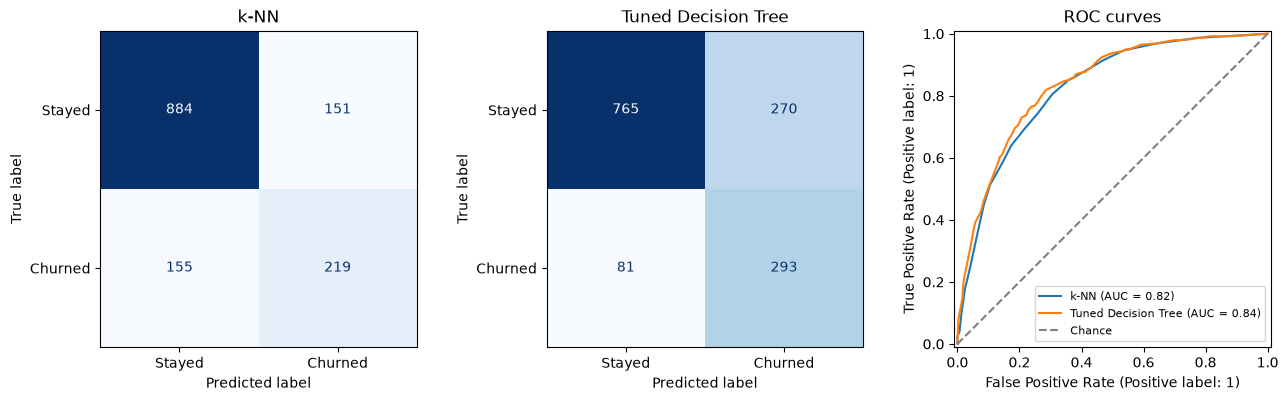

,Model,Accuracy,F1 (churn),Precision (churn),Recall (churn),ROC AUC
0,k-NN,0.7828,0.5887,0.5919,0.5856,0.824
1,Tuned Decision Tree,0.7509,0.6254,0.5204,0.7834,0.837


In [6]:
# Refit k-NN and use the tree already refit by GridSearchCV.
knn.fit(X_train, y_train)
classifiers = {"k-NN": knn, "Tuned Decision Tree": search.best_estimator_}
test_rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), layout="constrained")

for index, (name, model) in enumerate(classifiers.items()):
    # Evaluate both models on the same customers at the default decision threshold.
    predicted = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    test_rows.append({
        "Model": name, "Accuracy": accuracy_score(y_test, predicted),
        "F1 (churn)": f1_score(y_test, predicted),
        "Precision (churn)": precision_score(y_test, predicted),
        "Recall (churn)": recall_score(y_test, predicted),
        "ROC AUC": roc_auc_score(y_test, probability),
    })
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, display_labels=["Stayed", "Churned"],
        colorbar=False, cmap="Blues", ax=axes[index],
    )
    axes[index].set_title(name)
    RocCurveDisplay.from_predictions(y_test, probability, name=name, ax=axes[2])

axes[2].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
axes[2].set_title("ROC curves")
axes[2].legend(loc="lower right", fontsize=8)
plt.show()
classification_results = pd.DataFrame(test_rows)
display(classification_results.round(4))

The grid chose depth 7 and at least 50 customers per leaf. Tuning raised the tree's mean validation F1 from 0.4987 to 0.6226. The fixed k-NN model scored 0.5936 on the same folds.

On the held-out set, k-NN had higher accuracy (78.3% versus 75.1%). The tuned tree had higher churn F1 (0.6254 versus 0.5887), ROC AUC (0.8370 versus 0.8240), and recall (78.3% versus 58.6%). We would choose the tuned tree for retention outreach because it caught more customers who churned. It also flagged more customers who stayed, so we would check how the outreach budget changes the best threshold.

## 3. Group customers with K-Means

We cluster customers using tenure, monthly charges, contract type, and internet service. We standardize the two numeric columns and one-hot encode the two categories so dollar and month values do not dominate the distances. We fix `k=3` to keep the profiles easy to compare and report a silhouette score to describe how clearly the groups separate. We use two principal components to draw the plot. K-Means itself uses all the transformed inputs.

We leave churn out of the clustering inputs and add it back only when describing the groups. This is an exploratory view of the full dataset.

Silhouette score (2,000 sampled customers): 0.356


,Customers,MedianTenure,MedianMonthlyCharges,MonthToMonthShare,ChurnRate
Cluster,,,,,
0,1705,27.0,20.250,0.3525,0.0792
1,3006,11.0,74.400,0.9248,0.4694
2,2332,60.0,89.925,0.2118,0.1385


InternetService,DSL,Fiber optic,No
Cluster,,,
0,0.1050,0.0000,0.895
1,0.4222,0.5778,0.000
2,0.4172,0.5828,0.000


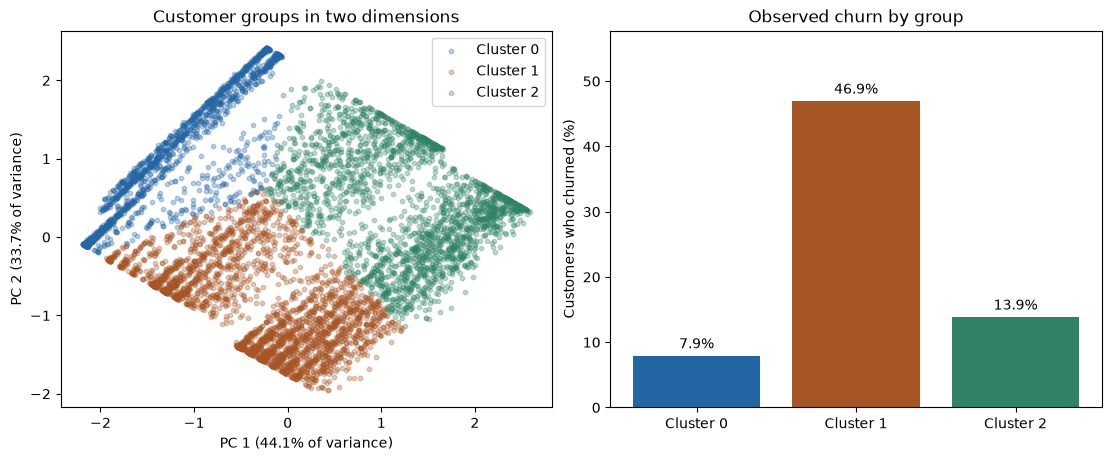

In [7]:
# Set up the unsupervised inputs and keep a copy for readable profiles.
cluster_inputs = df[["tenure", "MonthlyCharges", "Contract", "InternetService"]].copy()
cluster_preprocessing = ColumnTransformer([
    ("numeric", StandardScaler(), ["tenure", "MonthlyCharges"]),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
     ["Contract", "InternetService"]),
])
cluster_matrix = cluster_preprocessing.fit_transform(cluster_inputs)

# Use multiple initializations and a fixed seed to make the groups reproducible.
cluster_model = KMeans(n_clusters=3, n_init=20, random_state=42)
cluster_ids = cluster_model.fit_predict(cluster_matrix)
silhouette = silhouette_score(cluster_matrix, cluster_ids, sample_size=2000, random_state=42)
print(f"Silhouette score (2,000 sampled customers): {silhouette:.3f}")

# Profile groups in the original units and add the observed churn rates afterward.
profile_data = cluster_inputs.assign(
    Cluster=cluster_ids, Churn=y, MonthToMonth=cluster_inputs["Contract"].eq("Month-to-month"),
)
cluster_profiles = profile_data.groupby("Cluster").agg(
    Customers=("Churn", "size"),
    MedianTenure=("tenure", "median"),
    MedianMonthlyCharges=("MonthlyCharges", "median"),
    MonthToMonthShare=("MonthToMonth", "mean"),
    ChurnRate=("Churn", "mean"),
)
internet_share = pd.crosstab(
    profile_data["Cluster"], profile_data["InternetService"], normalize="index",
)
display(cluster_profiles.round(4))
display(internet_share.round(4))

# Project to two dimensions for visualization and label each group's churn rate.
pca = PCA(n_components=2)
projection = pca.fit_transform(cluster_matrix)
fig, (scatter, rate_ax) = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
colors = ["#2465a4", "#a75525", "#308365"]

for cluster, color in enumerate(colors):
    in_cluster = cluster_ids == cluster
    scatter.scatter(
        projection[in_cluster, 0], projection[in_cluster, 1],
        color=color, alpha=0.30, s=10, label=f"Cluster {cluster}",
    )

scatter.set(title="Customer groups in two dimensions",
            xlabel=f"PC 1 ({pca.explained_variance_ratio_[0]:.1%} of variance)",
            ylabel=f"PC 2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
scatter.legend()
rates = 100 * cluster_profiles["ChurnRate"]
bars = rate_ax.bar([f"Cluster {i}" for i in rates.index], rates, color=colors)
rate_ax.bar_label(bars, fmt="%.1f%%", padding=3)
rate_ax.set(title="Observed churn by group", ylabel="Customers who churned (%)",
            ylim=(0, rates.max() * 1.23))
plt.show()

| Cluster | Customers | What stands out | Observed churn |
| --- | ---: | --- | ---: |
| 0 | 1,705 | Mostly no internet service and a median monthly bill of 20.25 dollars | 7.9% |
| 1 | 3,006 | Median tenure of 11 months and about 92.5% on month-to-month contracts | 46.9% |
| 2 | 2,332 | Median tenure of 60 months and a median monthly bill of about 89.93 dollars | 13.9% |

Cluster 1 is where we would start testing a welcome check-in or a service review. Its observed churn rate was much higher than the overall rate of 26.5%. The silhouette score of 0.356 suggests some separation and some overlap, so we would use the groups to plan outreach and measure its effect before relying on the group labels.

## 4. Mine association rules with Apriori

For this analysis, each customer's account is a basket of attributes. We use contract, internet service, payment method, tech support, and churn. Apriori finds itemsets present in at least **4% of customers**, and we keep rules with **35% confidence or higher** that point to `Churn=Yes` and have **lift above 1**. We limit antecedents to two attributes for readability and remove longer rules when a shorter rule has at least the same confidence.

**Support** is the share of all customers with both sides of the rule. **Confidence** is the share with the left side who churned. **Lift** divides confidence by the overall churn rate. A lift of 2 means the observed churn rate for that group was twice the overall rate. [mlxtend Apriori and association rules](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/association_rules/)

Frequent itemsets: 187; churn rules after filtering: 10


,Conditions,support,confidence,lift
105,Contract=Month-to-month + InternetService=Fiber optic,0.1650,0.5461,2.0577
132,Contract=Month-to-month + PaymentMethod=Electronic check,0.1411,0.5373,2.0247
264,InternetService=Fiber optic + PaymentMethod=Electronic check,0.1205,0.5323,2.0058
314,PaymentMethod=Electronic check + TechSupport=No,0.1306,0.5318,2.0040
150,Contract=Month-to-month + TechSupport=No,0.1917,0.5037,1.8982
273,InternetService=Fiber optic + TechSupport=No,0.1563,0.4937,1.8605


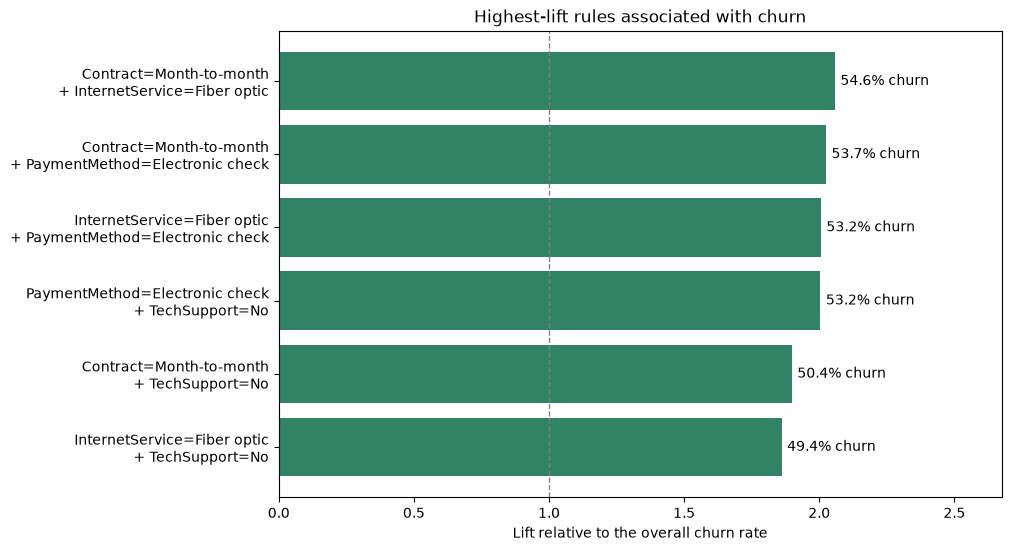

In [8]:
# Turn each account attribute into a true/false item for Apriori.
rule_columns = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "Churn"]
transactions = pd.get_dummies(df[rule_columns], prefix_sep="=", dtype=bool)
itemsets = apriori(transactions, min_support=0.04, use_colnames=True, max_len=3)
rules = association_rules(itemsets, metric="confidence", min_threshold=0.35)
target = frozenset({"Churn=Yes"})

# Keep rules pointing to churn and skip any that already use churn as an input.
candidate_rules = rules.loc[
    rules["consequents"].eq(target)
    & rules["antecedents"].map(lambda items: all(not item.startswith("Churn=") for item in items))
    & rules["lift"].gt(1)
].copy()

# Remove combinations that do no better than an available simpler rule.
confidence_by_antecedent = dict(zip(candidate_rules["antecedents"], candidate_rules["confidence"]))
keep = [
    not any(shorter < row.antecedents and confidence >= row.confidence
            for shorter, confidence in confidence_by_antecedent.items())
    for row in candidate_rules.itertuples()
]
churn_rules = candidate_rules.loc[keep].copy()
churn_rules["Conditions"] = churn_rules["antecedents"].map(lambda items: " + ".join(sorted(items)))
churn_rules = churn_rules.sort_values(["lift", "support", "Conditions"], ascending=[False, False, True])
top_rules = churn_rules.head(6)
print(f"Frequent itemsets: {len(itemsets):,}; churn rules after filtering: {len(churn_rules):,}")
with pd.option_context("display.max_colwidth", None):
    display(top_rules[["Conditions", "support", "confidence", "lift"]].round(4))

# Plot lift for a short list of highest-lift rules, with churn rates on the bars.
plot_rules = top_rules.sort_values("lift")
labels = [label.replace(" + ", "\n+ ") for label in plot_rules["Conditions"]]
fig, ax = plt.subplots(figsize=(10, 5.4), layout="constrained")
bars = ax.barh(labels, plot_rules["lift"], color="#308365")
ax.bar_label(bars, labels=[f"{value:.1%} churn" for value in plot_rules["confidence"]], padding=4)
ax.axvline(1, linestyle="--", linewidth=1, color="gray")
ax.set(title="Highest-lift rules associated with churn",
       xlabel="Lift relative to the overall churn rate",
       xlim=(0, plot_rules["lift"].max() * 1.30))
plt.show()

The highest-lift rule paired a month-to-month contract with fiber optic service. That pair and churn occurred together for 16.5% of all customers. Among customers with the pair, 54.6% churned, about 2.06 times the overall churn rate. Customers with a month-to-month contract who paid by electronic check also had a high observed churn rate (53.7%, lift 2.02).

## 5. Real-world applications of the discovered patterns

We would use these rules to pick groups for a small retention test. For example, we could offer a service check-in to a random subset of month-to-month fiber customers and compare churn against a group that receives usual support. Contract type, service, and payment method can overlap, so these associations give us a place to investigate before deciding what to change.